In [1]:
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
from cartopy.util import add_cyclic_point
from pathlib import Path
import xcdat as xc
import cmasher as cmr
import xarray as xr
import sys

sys.path.append('../../functions/')
from lag_linregress import *
from monthly_departures import *
from MCA import *

# Reload edited Python modules automatically before running subsequent cells.
%load_ext autoreload
%autoreload 2

import sys

# Add the project folder only once, even if this cell is rerun.
functions_path = "/scratch/leiff/MCA/amip_clean/project_functions/"
if functions_path not in sys.path:
    sys.path.append(functions_path)

from MCA_cov import *
from significance import *
from plotting import *
from diagnostics import *
# from taylor_setup import *
from setup_diagnostic import *

In [2]:
# 1. Imports and settings
from pathlib import Path
from copy import deepcopy
from datetime import datetime, timezone
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# These are HPC paths. Change archive_dir only if you have copied the archive.
# No raw climate data, new detrending, or existing model/MMM aggregates are used.
archive_dir = Path('/scratch/leiff/MCA/amip_clean/data/maps_2000_2014_covImp/overlap_core_200003_201412')
results_dir = archive_dir / 'figure1_diagnostic_variants' / 'run_01'
models_to_use = None                    # None = the AMIP/historical model intersection.
identity_rtol, identity_atol = 2e-5, 1e-8
save_results, load_results, overwrite = False, False, False

# Use an override ONLY after verifying the exact archive-axis order from source
# provenance. Never infer CMIP member labels from integer positions or counts.
# Example: {('historical', 'CanESM5'): {'labels': [...], 'evidence': 'file + check'}}
member_label_overrides = {}

# Figure choices. All row limits are shared across the three dataset columns.
plot_method, color_binning = 'pcolormesh', 'discrete'
cmap_name, central_longitude = 'cmr.fusion_r', 210
show_regions, show_stippling, save_figures = True, True, False
fdr_q, sign_threshold = 0.05, 0.80
figure_dpi = 200

In [3]:
# 2. Load the member archive and inspect its metadata
# Load only trusted pickle-containing files. The old model/MMM summaries and
# vs_obs scores are deliberately not loaded: their CanESM5 selection may be old.
archive_names = ['overlap_member_values', 'overlap_observations', 'overlap_coordinates',
                 'overlap_model_names', 'overlap_member_ids', 'overlap_quantity_info',
                 'overlap_sources', 'overlap_metadata']
missing_files = [name + '.npy' for name in archive_names if not (archive_dir / (name + '.npy')).exists()]
if missing_files:
    raise FileNotFoundError(f'Archive not available at {archive_dir}. Missing: {missing_files}')
archive = {name: np.load(archive_dir / (name + '.npy'), allow_pickle=True).item() for name in archive_names}
source_values = archive['overlap_member_values']
source_observations = archive['overlap_observations']
source_coordinates = archive['overlap_coordinates']
source_model_names = archive['overlap_model_names']
source_member_ids = archive['overlap_member_ids']
source_metadata = archive['overlap_metadata']
historical_source = 'historical' if 'historical' in source_values else 'historical_matched'
print('Archive:', archive_dir)
print('Registered quantities:', list(archive['overlap_quantity_info']))
display(pd.Series(source_metadata, name='saved setting').to_frame())
print('Radiation sign and units are preserved from the input archive; no sign is flipped here.')
print('Intended N = rsdt - rsut - rlut, positive downward. Check raw metadata if its sign is unverified.')

Archive: /scratch/leiff/MCA/amip_clean/data/maps_2000_2014_covImp/overlap_core_200003_201412
Registered quantities: ['corr_Ti_Ri', 'corr_T_Ri', 'corr_Ti_R', 'corr_T_R', 'sigma_Ti', 'sigma_Ri', 'sigma_T', 'sigma_R', 'T_detrended', 'R_detrended', 'T_trend_in', 'R_trend_in', 'cov_Zi_R', 'cov_Ti_R', 'cov_T_Qi', 'cov_T_Ri', 'cov_Zi_Ri', 'cov_Ti_Qi', 'cov_Ti_Ri']


,saved setting
schema_version,1
created_utc,2026-09-11T21:55:18.708173+00:00
start_month,2000-03
end_month,2014-12
n_time,178
ddof,1
detrending_function,detrend_monthly_fast
detrending_source,"def detrend_monthly_fast(arr):\n """"""Detrend..."
preprocessing,User's monthwise detrend/deseasonalize; then c...
trend_in_series,Subtract each calendar month's mean within the...


Radiation sign and units are preserved from the input archive; no sign is flipped here.
Intended N = rsdt - rsut - rlut, positive downward. Check raw metadata if its sign is unverified.


In [4]:
# 3. Check dates, weights, support, and member labels; select CanESM5 p2
lat, lon = [np.asarray(source_coordinates[key], dtype=float) for key in ['lat', 'lon']]
times = np.asarray(source_coordinates['time']).astype('datetime64[M]')
expected_months = np.arange(np.datetime64('2000-03'), np.datetime64('2015-01'), dtype='datetime64[M]')
if not np.array_equal(times, expected_months):
    raise ValueError('This comparison requires exactly March 2000–December 2014 (178 months).')
if lat.ndim != 1 or lon.ndim != 1 or not np.isfinite(lat).all() or not np.isfinite(lon).all():
    raise ValueError('Expected finite 1-D coordinates.')
if not (np.all(np.diff(lat) > 0) and np.all(np.diff(lon) > 0)):
    raise ValueError('Coordinates must increase; reorder DATA and coordinates together upstream.')
grid_shape = (len(lat), len(lon))
base_weights, global_weights = [np.asarray(source_coordinates[key], dtype=float)
                                for key in ['base_weights', 'global_weights']]
local_support = np.asarray(source_coordinates['local_support'], dtype=bool)
for weights in [base_weights, global_weights]:
    if weights.shape != grid_shape or not np.isfinite(weights).all() or np.any(weights < 0):
        raise ValueError('Saved weights must be finite, nonnegative, and match the grid.')
    np.testing.assert_allclose(weights.sum(), 1., rtol=0, atol=1e-10)
if local_support.shape != grid_shape or not local_support.any():
    raise ValueError('Saved local_support must be a nonempty grid mask.')
if not np.allclose(global_weights, base_weights, rtol=0, atol=1e-12):
    raise ValueError('Saved indices use a restricted domain. They cannot be labelled global in these figures.')
ddof = source_metadata.get('ddof')
if not isinstance(ddof, (int, np.integer)) or not 0 <= ddof < len(times):
    raise ValueError('The archive must record its temporal ddof.')
if source_metadata.get('detrending_function') != 'detrend_monthly_fast':
    raise ValueError('This notebook requires recorded use of the user\'s detrend_monthly_fast.')
if source_metadata.get('n_time') != len(times):
    raise ValueError('The saved metadata and time coordinate disagree about sample count.')
print(f'Grid: {grid_shape}; months: {len(times)}; temporal ddof: {ddof}')
print('Preprocessing:', source_metadata.get('preprocessing', 'NOT RECORDED'))
print('Detrending source saved:', bool(source_metadata.get('detrending_source')))
print('The compact archive cannot independently recheck raw-field preprocessing or local SDs.')

# Match MODELS across experiments, keeping all selected members within each model.
# AMIP and historical member numbers are not synchronized realizations.
for group in ['amip_hist', historical_source]:
    names = list(source_model_names[group])
    if not names or len(names) != len(set(names)):
        raise ValueError(f'{group}: model labels are empty or duplicated.')
matched_models = [m for m in source_model_names['amip_hist'] if m in source_model_names[historical_source]]
if models_to_use is not None:
    if not models_to_use or len(models_to_use) != len(set(models_to_use)) or not set(models_to_use) <= set(matched_models):
        raise ValueError('models_to_use must be a nonempty, unique subset of the matched models.')
    matched_models = list(models_to_use)
if not matched_models:
    raise ValueError('No matched models remain.')
experiment_sources = {'historical_matched': historical_source, 'amip_hist': 'amip_hist'}
diagnostic_model_names = {exp: matched_models.copy() for exp in experiment_sources}
diagnostic_member_ids = {exp: {} for exp in experiment_sources}
member_selection, selection_rows = {exp: {} for exp in experiment_sources}, []
member_pattern = re.compile(r'r(\d+)i(\d+)p(\d+)f(\d+)')
for experiment, source in experiment_sources.items():
    for model in matched_models:
        archive_ids = np.asarray(source_member_ids[source][model])
        labels = np.array([x.decode() if isinstance(x, bytes) else str(x) for x in archive_ids])
        override = member_label_overrides.get((source, model))
        evidence = 'saved archive member labels'
        if override is not None:
            labels, evidence = np.asarray(override['labels'], dtype=str), override['evidence']
            if labels.shape != archive_ids.shape or not str(evidence).strip():
                raise ValueError('An override needs one verified label per archive member and provenance.')
        if labels.ndim != 1 or not len(labels) or len(set(labels)) != len(labels):
            raise ValueError(f'{source}/{model}: missing or duplicated member labels.')
        keep = np.ones(len(labels), dtype=bool)
        if model == 'CanESM5':
            parsed = [member_pattern.fullmatch(label) for label in labels]
            if any(match is None for match in parsed):
                raise ValueError('CanESM5 physics cannot be verified from these IDs. Supply an explicitly verified '
                                 'member_label_overrides entry, or regenerate labelled member diagnostics.')
            keep = np.array([int(match.group(3)) == 2 for match in parsed])
            if not keep.any():
                raise ValueError(f'{source}/CanESM5 has no p2 members. No p1 substitution is allowed.')
        member_selection[experiment][model] = np.flatnonzero(keep)
        diagnostic_member_ids[experiment][model] = labels[keep]
        selection_rows.append({'experiment': experiment, 'model': model, 'source_group': source,
                               'archive_members': len(labels), 'selected_members': int(keep.sum()),
                               'excluded_members': int((~keep).sum()), 'label_evidence': evidence,
                               'archive_ids': archive_ids.tolist(), 'selected_labels': labels[keep].tolist()})
selection_table = pd.DataFrame(selection_rows)
display(selection_table.drop(columns=['archive_ids', 'selected_labels']))

# Embedded snapshot of region_definitions.py, adopted 27 October 2026.
# This notebook needs no separate local Python file. The shared project source
# remains authoritative; regenerate this snapshot if the adopted regions change.
# Geographic masks include land. Outlines do not restrict the scoring domain.
region_version = '2026-10-27_SEP110W_NEP142W_WPWP-original'
adopted_regions = {
    'SEP': {'lat_range': (-35.0, -5.0), 'west': 250.0, 'east_at_south': 290.0, 'east_at_north': 280.0},
    'NEP': {'lat_range': (15.0, 38.0), 'west': 218.0, 'east_at_south': 255.0, 'east_at_north': 235.0},
    'WPWP': {'lat_range': (-10.0, 10.0), 'west': 80.0, 'east_at_south': 150.0, 'east_at_north': 150.0},
}

# Compare grid centers with the geographic boundaries. Eastern edges taper
# linearly with latitude. WPWP keeps its original Maritime Continent coverage.
latitude, longitude = lat[:, None], (lon % 360.)[None, :]
region_masks, region_outlines = {}, {}
for name, region in adopted_regions.items():
    south, north = region['lat_range']
    west, east_south, east_north = [region[key] for key in ['west', 'east_at_south', 'east_at_north']]
    east_limit = east_south + (east_north - east_south) * (latitude - south) / (north - south)
    region_masks[name] = ((latitude >= south) & (latitude <= north)
                          & (longitude >= west) & (longitude <= east_limit))
    region_outlines[name] = np.array([[west, south], [east_south, south],
                                      [east_north, north], [west, north]])
diagnostic_regions = {'version': region_version, 'definitions': deepcopy(adopted_regions),
                      'masks': region_masks, 'vertices': region_outlines,
                      'definition_source': 'Embedded snapshot of project region_definitions.py'}
diagnostic_coordinates = deepcopy(source_coordinates)
diagnostic_metadata = {'created_utc': datetime.now(timezone.utc).isoformat(), 'source_archive': str(archive_dir),
                       'source_metadata': deepcopy(source_metadata), 'source_quantity_info': deepcopy(archive['overlap_quantity_info']),
                       'source_provenance': deepcopy(archive['overlap_sources']), 'selection': selection_rows,
                       'physics_selection': 'CanESM5 p2 only; other models unchanged',
                       'aggregation': 'Arithmetic member means, then equal-model means; no Fisher-z',
                       'identity_rtol': identity_rtol, 'identity_atol': identity_atol,
                       'radiation_sign': 'Input sign preserved; downward-positive intended, not newly verified',
                       'region_version': diagnostic_regions['version']}

Grid: (72, 144); months: 178; temporal ddof: 1
Preprocessing: User's monthwise detrend/deseasonalize; then center through time
Detrending source saved: True
The compact archive cannot independently recheck raw-field preprocessing or local SDs.


,experiment,model,source_group,archive_members,selected_members,excluded_members,label_evidence
0,historical_matched,BCC-CSM2-MR,historical,3,3,0,saved archive member labels
1,historical_matched,CAMS-CSM1-0,historical,3,3,0,saved archive member labels
2,historical_matched,CESM2,historical,11,11,0,saved archive member labels
3,historical_matched,CIESM,historical,3,3,0,saved archive member labels
4,historical_matched,CNRM-CM6-1,historical,29,29,0,saved archive member labels
5,historical_matched,CNRM-CM6-1-HR,historical,1,1,0,saved archive member labels
6,historical_matched,CNRM-ESM2-1,historical,10,10,0,saved archive member labels
7,historical_matched,CanESM5,historical,65,40,25,saved archive member labels
8,historical_matched,FGOALS-f3-L,historical,3,3,0,saved archive member labels
9,historical_matched,FGOALS-g3,historical,6,6,0,saved archive member labels


In [5]:
# 4. Reconstruct member diagnostics and check them against saved covariances
# All covariances and sigmas use the archive's same samples and temporal ddof.
# Temperature is tas/t2m, not prescribed SST. sigma_R is a global SERIES SD.
required_keys = ['corr_Ti_R', 'corr_Ti_Ri', 'sigma_Ti', 'sigma_Ri', 'sigma_T', 'sigma_R',
                 'T_detrended', 'R_detrended']
diagnostic_quantity_info = {
    'corr_Ti_R': {'kind': 'map', 'units': '1', 'definition': 'Corr(T_i, R_g)'},
    'corr_Ti_Ri': {'kind': 'map', 'units': '1', 'definition': 'Corr(T_i, R_i)'},
    'sigma_Ti': {'kind': 'map', 'units': 'K', 'definition': 'SD(T_i)'},
    'sigma_Ri': {'kind': 'map', 'units': 'W m-2', 'definition': 'SD(R_i)'},
    'sigma_T': {'kind': 'scalar', 'units': 'K', 'definition': 'SD(T_g)'},
    'sigma_R': {'kind': 'scalar', 'units': 'W m-2', 'definition': 'SD(R_g)'},
    'T_detrended': {'kind': 'series', 'units': 'K', 'definition': 'Processed global temperature'},
    'R_detrended': {'kind': 'series', 'units': 'W m-2', 'definition': 'Processed global net TOA radiation'},
    'cov_Ti_R': {'kind': 'map', 'units': 'K W m-2', 'definition': 'Cov(T_i, R_g)'},
    'cov_Ti_Ri': {'kind': 'map', 'units': 'K W m-2', 'definition': 'Cov(T_i, R_i)'},
    'cov_Zi_R': {'kind': 'map', 'units': 'W m-2', 'definition': 'Cov(T_i / SD(T_i), R_g)'},
    'cov_Zi_Ri': {'kind': 'map', 'units': 'W m-2', 'definition': 'Cov(T_i / SD(T_i), R_i)'},
}
identity_rows = []

def reconstruct_diagnostics(values, label):
    """One member or observation: input maps are (lat,lon), globals are scalars."""
    values = {key: np.asarray(value, dtype=float) for key, value in values.items()}
    for key in required_keys:
        if key not in values:
            raise KeyError(f'{label}: missing {key}')
        kind = diagnostic_quantity_info[key]['kind']
        expected = {'map': grid_shape, 'scalar': (), 'series': (len(times),)}[kind]
        if values[key].shape != expected:
            raise ValueError(f'{label}/{key}: expected {expected}, got {values[key].shape}')
    result = {key: values[key].copy() for key in required_keys}
    sTi, sRi, sT, sR = [values[key] for key in ['sigma_Ti', 'sigma_Ri', 'sigma_T', 'sigma_R']]
    for key in ['sigma_Ti', 'sigma_Ri', 'sigma_T', 'sigma_R']:
        if np.any(np.isfinite(values[key]) & (values[key] < 0)):
            raise ValueError(f'{label}: negative SD in {key}')
    for key in ['corr_Ti_R', 'corr_Ti_Ri']:
        if np.any(np.abs(values[key][np.isfinite(values[key])]) > 1 + identity_atol):
            raise ValueError(f'{label}: correlation outside [-1, 1]')

    # Raw covariance is zero for a finite constant variable, even when correlation
    # is undefined. A standardized constant TEMPERATURE predictor stays undefined.
    for suffix, rho, response_sd in [('R', values['corr_Ti_R'], sR),
                                      ('Ri', values['corr_Ti_Ri'], sRi)]:
        finite_sd = np.isfinite(sTi) & np.isfinite(response_sd)
        raw_cov = np.where(finite_sd & ((sTi == 0) | (response_sd == 0)), 0., rho * sTi * response_sd)
        standard_cov = np.divide(raw_cov, sTi, out=np.full(grid_shape, np.nan), where=sTi > 0)
        for key, reconstructed in [('cov_Ti_' + suffix, raw_cov), ('cov_Zi_' + suffix, standard_cov)]:
            reconstructed = np.where(local_support, reconstructed, np.nan)
            independently_saved = key in values
            if independently_saved:
                if values[key].shape != grid_shape:
                    raise ValueError(f'{label}/{key}: saved covariance must match the grid.')
                np.testing.assert_allclose(values[key], reconstructed, rtol=identity_rtol,
                                           atol=identity_atol, equal_nan=True, err_msg=f'{label}/{key}')
                finite = np.isfinite(values[key]) & np.isfinite(reconstructed)
                max_error = float(np.max(np.abs(values[key][finite] - reconstructed[finite]))) if finite.any() else np.nan
                result[key] = values[key].copy()
            else:
                max_error, result[key] = np.nan, reconstructed
            identity_rows.append({'dataset': label, 'quantity': key, 'independent_saved_check': independently_saved,
                                  'max_absolute_error': max_error,
                                  'note': 'saved covariance checked' if independently_saved else 'reconstructed only; no independent covariance saved'})

    # Unlike local maps, these global time series are retained. Check their SDs
    # directly and verify that processed series are centered within tolerance.
    for series_key, sigma_key in [('T_detrended', 'sigma_T'), ('R_detrended', 'sigma_R')]:
        series = values[series_key]
        if not np.isfinite(series).all():
            raise ValueError(f'{label}/{series_key}: missing months')
        np.testing.assert_allclose(series.std(ddof=ddof), values[sigma_key], rtol=identity_rtol, atol=identity_atol)
        np.testing.assert_allclose(series.mean(), 0., atol=identity_atol * max(1., float(values[sigma_key])))
    return result

diagnostic_observations = reconstruct_diagnostics(source_observations, 'observations')
diagnostic_member_values = {exp: {key: {} for key in diagnostic_quantity_info} for exp in experiment_sources}
for experiment, source in experiment_sources.items():
    for model in matched_models:
        selected = member_selection[experiment][model]
        available = source_values[source]
        n_archive = len(source_member_ids[source][model])
        member_inputs = {}
        for key in required_keys + ['cov_Ti_R', 'cov_Ti_Ri', 'cov_Zi_R', 'cov_Zi_Ri']:
            if key in available and model in available[key]:
                array = np.asarray(available[key][model], dtype=float)
                if array.shape[0] != n_archive:
                    raise ValueError(f'{source}/{model}/{key}: member axis does not match saved IDs.')
                member_inputs[key] = array[selected]
        calculated = []
        for index, member in enumerate(diagnostic_member_ids[experiment][model]):
            calculated.append(reconstruct_diagnostics({key: value[index] for key, value in member_inputs.items()},
                                                      f'{experiment}/{model}/{member}'))
        for key in diagnostic_quantity_info:
            diagnostic_member_values[experiment][key][model] = np.stack([value[key] for value in calculated])
identity_table = pd.DataFrame(identity_rows)
display(identity_table.groupby(['quantity', 'independent_saved_check'], dropna=False)['max_absolute_error'].agg(['count', 'max']))
print('Rows marked reconstructed only are algebraic constructions, not independent validation.')

,,count,max
quantity,independent_saved_check,,
cov_Ti_R,True,177,2.220446e-16
cov_Ti_Ri,True,177,7.105427e-15
cov_Zi_R,True,177,2.220446e-16
cov_Zi_Ri,True,177,7.105427e-15


Rows marked reconstructed only are algebraic constructions, not independent validation.


In [6]:
# 5. Recompute model means and equal-model MMMs after member selection
def mean_and_count(values):
    """Finite arithmetic mean over the first axis, with explicit contributor counts."""
    values = np.asarray(values, dtype=float)
    finite = np.isfinite(values)
    count, total = finite.sum(axis=0), np.where(finite, values, 0.).sum(axis=0)
    mean = np.divide(total, count, out=np.full_like(total, np.nan), where=count > 0)
    return mean, count

diagnostic_model_means, diagnostic_model_n_valid = {}, {}
diagnostic_MMM, diagnostic_MMM_n_valid = {}, {}
for experiment, models in diagnostic_model_names.items():
    diagnostic_model_means[experiment], diagnostic_model_n_valid[experiment] = {}, {}
    diagnostic_MMM[experiment], diagnostic_MMM_n_valid[experiment] = {}, {}
    for key in diagnostic_quantity_info:
        model_results = [mean_and_count(diagnostic_member_values[experiment][key][model]) for model in models]
        diagnostic_model_means[experiment][key] = np.stack([value[0] for value in model_results])
        diagnostic_model_n_valid[experiment][key] = np.stack([value[1] for value in model_results])
        diagnostic_MMM[experiment][key], diagnostic_MMM_n_valid[experiment][key] = mean_and_count(
            diagnostic_model_means[experiment][key])
print('Means rebuilt from selected members. MMM maps average diagnostics, not monthly ensemble-mean fields.')

Means rebuilt from selected members. MMM maps average diagnostics, not monthly ensemble-mean fields.


In [7]:
# 6. Calculate the two distinct regressions and the global-budget density
# Divisions occur PER MEMBER. An inverse-variance weighting introduced after
# averaging would answer a different question. Constant local T gives no slope.
extra_info = {
    'thompson_global': {'kind': 'map', 'units': 'W m-2 K-1', 'definition': 'Cov(T_i,R_g) / Var(T_g)'},
    'reg_R_on_Ti': {'kind': 'map', 'units': 'W m-2 K-1', 'definition': 'Cov(T_i,R_g) / Var(T_i)'},
    'reg_Ri_on_Ti': {'kind': 'map', 'units': 'W m-2 K-1', 'definition': 'Cov(T_i,R_i) / Var(T_i)'},
}

def add_slope_maps(values):
    """One-member dictionaries; local maps are (lat,lon), global SD is scalar."""
    result = dict(values)
    local_variance, global_variance = values['sigma_Ti']**2, float(values['sigma_T'])**2
    for key, covariance in [('reg_R_on_Ti', values['cov_Ti_R']), ('reg_Ri_on_Ti', values['cov_Ti_Ri'])]:
        result[key] = np.divide(covariance, local_variance, out=np.full(grid_shape, np.nan), where=local_variance > 0)
    result['thompson_global'] = (values['cov_Ti_R'] / global_variance if global_variance > 0
                                 else np.full(grid_shape, np.nan))
    return result

diagnostic_observations = add_slope_maps(diagnostic_observations)
for experiment, models in diagnostic_model_names.items():
    diagnostic_member_values[experiment].update({key: {} for key in extra_info})
    for model in models:
        calculated = [add_slope_maps({key: diagnostic_member_values[experiment][key][model][index]
                                     for key in diagnostic_quantity_info})
                      for index in range(len(diagnostic_member_ids[experiment][model]))]
        for key in extra_info:
            diagnostic_member_values[experiment][key][model] = np.stack([result[key] for result in calculated])
diagnostic_quantity_info.update(extra_info)

# Compare the weighted full-map budget against OLS from the saved global series.
# A restricted local-map domain cannot establish global closure: report coverage
# and retain the partial contribution, rather than silently renormalizing weights.
budget_rows = []
datasets = [('observations', diagnostic_observations)]
for experiment, models in diagnostic_model_names.items():
    for model in models:
        for index, member in enumerate(diagnostic_member_ids[experiment][model]):
            datasets.append((f'{experiment}/{model}/{member}',
                             {key: diagnostic_member_values[experiment][key][model][index] for key in diagnostic_quantity_info}))
for label, values in datasets:
    T, R, L = values['T_detrended'], values['R_detrended'], values['thompson_global']
    T, R = T - T.mean(), R - R.mean()
    ols = float(np.dot(T, R) / np.dot(T, T)) if np.dot(T, T) > 0 else np.nan
    supported = (global_weights > 0) & np.isfinite(L)
    complete = bool(np.all(np.isfinite(L[global_weights > 0])))
    partial = float(np.sum(global_weights[supported] * L[supported]))
    if complete and np.isfinite(ols):
        np.testing.assert_allclose(partial, ols, rtol=identity_rtol, atol=identity_atol, err_msg=label)
    budget_rows.append({'dataset': label, 'global_OLS': ols, 'available_map_contribution': partial,
                        'global_weight_covered': float(global_weights[supported].sum()),
                        'full_budget_checked': complete and np.isfinite(ols),
                        'sum_minus_OLS': partial - ols if complete and np.isfinite(ols) else np.nan})
budget_table = pd.DataFrame(budget_rows)
display(budget_table)

,dataset,global_OLS,available_map_contribution,global_weight_covered,full_budget_checked,sum_minus_OLS
0,observations,-1.563257,-1.563257,1.0,True,-2.220446e-16
1,historical_matched/BCC-CSM2-MR/r1i1p1f1,-0.159527,-0.159527,1.0,True,2.775558e-17
2,historical_matched/BCC-CSM2-MR/r2i1p1f1,-1.113268,-1.113268,1.0,True,4.440892e-16
3,historical_matched/BCC-CSM2-MR/r3i1p1f1,-0.685904,-0.685904,1.0,True,0.000000e+00
4,historical_matched/CAMS-CSM1-0/r1i1p1f1,-1.338616,-1.338616,1.0,True,0.000000e+00
...,...,...,...,...,...,...
172,amip_hist/MRI-ESM2-0/r4i1p1f1,-1.443387,-1.443387,1.0,True,2.220446e-16
173,amip_hist/MRI-ESM2-0/r5i1p1f1,-2.185273,-2.185273,1.0,True,4.440892e-16
174,amip_hist/TaiESM1/r1i1p1f1,-1.481827,-1.481827,1.0,True,0.000000e+00
175,amip_hist/TaiESM1/r2i1p1f1,-1.481827,-1.481827,1.0,True,0.000000e+00


In [8]:
# 7. Recompute variant means and choose one common display domain
variant_pairs = {
    '01_raw_covariance': ('cov_Ti_R', 'cov_Ti_Ri'),
    '02_standardized_temperature': ('cov_Zi_R', 'cov_Zi_Ri'),
    '03_correlation': ('corr_Ti_R', 'corr_Ti_Ri'),
    '04_global_budget_and_local_regression': ('thompson_global', 'reg_Ri_on_Ti'),
    '05_local_predictor_regressions': ('reg_R_on_Ti', 'reg_Ri_on_Ti'),
}
variant_keys = list(dict.fromkeys(key for pair in variant_pairs.values() for key in pair))
variant_model_means, variant_model_n_valid, variant_MMM, variant_MMM_n_valid = {}, {}, {}, {}
for experiment, models in diagnostic_model_names.items():
    variant_model_means[experiment], variant_model_n_valid[experiment] = {}, {}
    variant_MMM[experiment], variant_MMM_n_valid[experiment] = {}, {}
    for key in variant_keys:
        means_counts = [mean_and_count(diagnostic_member_values[experiment][key][model]) for model in models]
        variant_model_means[experiment][key] = np.stack([value[0] for value in means_counts])
        variant_model_n_valid[experiment][key] = np.stack([value[1] for value in means_counts])
        variant_MMM[experiment][key], variant_MMM_n_valid[experiment][key] = mean_and_count(variant_model_means[experiment][key])

# A visual change should not arise just because a different subset of cells or
# members contributed. Default to the intersection of finite MEMBER maps across
# all five definitions, both experiments, and observations. Nothing is zero-filled.
variant_display_mask = local_support & (base_weights > 0)
for key in variant_keys:
    variant_display_mask &= np.isfinite(diagnostic_observations[key])
    for experiment, models in diagnostic_model_names.items():
        for model in models:
            variant_display_mask &= np.isfinite(diagnostic_member_values[experiment][key][model]).all(axis=0)
if not variant_display_mask.any():
    raise ValueError('No cells are finite for all requested diagnostics/members. Inspect degeneracy before selecting a different domain.')
print('Common display:', int(variant_display_mask.sum()), 'cells;',
      f'{base_weights[variant_display_mask].sum()/base_weights[local_support].sum():.2%} of saved local-domain area.')
print('Budget checks above use the original available domain, BEFORE this display-only intersection.')

# Preserve Figure 1 scales for the standardized-T pair; correlations use [-1,1].
# Other limits include every displayed value across all three columns. Change a
# particular key explicitly for a closer view; repeated rows always reuse its scale.
variant_vlims = {key: None for key in variant_keys}
variant_vlims.update(cov_Zi_R=0.25, cov_Zi_Ri=7.5, corr_Ti_R=1., corr_Ti_Ri=1.)
for key in variant_keys:
    if variant_vlims[key] is None:
        maps = np.stack([diagnostic_observations[key], variant_MMM['historical_matched'][key], variant_MMM['amip_hist'][key]])
        maximum = float(np.max(np.abs(maps[:, variant_display_mask])))
        variant_vlims[key] = maximum if maximum > 0 else 1.
diagnostic_metadata.update(variant_pairs=variant_pairs, variant_display_mask=variant_display_mask,
                           variant_vlims=variant_vlims, robustness={'q': fdr_q, 'agreement_threshold': sign_threshold},
                           Thompson_interpretation='Temperature-indexed contribution density Cov(T_i,R_g)/Var(T_g)')

Common display: 10368 cells; 100.00% of saved local-domain area.
Budget checks above use the original available domain, BEFORE this display-only intersection.


In [9]:
# Plotting function — shared row scales, adopted regions, and new robustness masks
import cartopy.crs as ccrs
from cartopy.util import add_cyclic_point
from matplotlib.colors import BoundaryNorm, Normalize
from scipy.stats import ttest_1samp
try:
    import cmasher                         # Registers the original cmr.fusion_r palette.
except ImportError:
    if cmap_name.startswith('cmr.'):
        cmap_name = 'RdBu_r'
        print('Cmasher is unavailable; using RdBu_r.')

def mean_and_count(values):
    """Finite arithmetic mean over the first axis, with explicit contributor counts."""
    values = np.asarray(values, dtype=float)
    finite = np.isfinite(values)
    count, total = finite.sum(axis=0), np.where(finite, values, 0.).sum(axis=0)
    mean = np.divide(total, count, out=np.full_like(total, np.nan), where=count > 0)
    return mean, count

def model_robustness(model_maps, *, q=0.05, agreement_threshold=0.80):
    """Original operational criterion: BH FDR AND >80% sign agreement with MMM."""
    model_maps = np.asarray(model_maps, dtype=float)
    mean_map, count = mean_and_count(model_maps)
    # The test samples MODEL MEANS, not members or 178 independent months.
    # Model dependence and unequal ensemble precision limit inferential meaning.
    pvalue = np.full(mean_map.shape, np.nan)
    eligible = count >= 2
    if eligible.any():
        pvalue[eligible] = ttest_1samp(model_maps[:, eligible], 0., axis=0, nan_policy='omit').pvalue
    adjusted = np.full(pvalue.shape, np.nan)
    flat = np.flatnonzero(np.isfinite(pvalue))
    if len(flat):
        ordered = flat[np.argsort(pvalue.ravel()[flat])]
        ranked = pvalue.ravel()[ordered] * len(ordered) / np.arange(1, len(ordered) + 1)
        adjusted.ravel()[ordered] = np.minimum(1., np.minimum.accumulate(ranked[::-1])[::-1])
    agree = np.sum(np.isfinite(model_maps) & (np.sign(model_maps) == np.sign(mean_map))
                   & (np.sign(mean_map) != 0), axis=0)
    fraction = np.divide(agree, count, out=np.full_like(mean_map, np.nan), where=count > 0)
    return {'n_valid': count, 'pvalue': pvalue, 'pvalue_fdr': adjusted, 'agreement_fraction': fraction,
            'robust': (adjusted <= q) & (fraction > agreement_threshold)}

def plot_figure1(maps, row_labels, colorbar_labels, title, coordinates, regions, *,
                 plot_method='pcolormesh', color_binning='discrete', vlims=None,
                 cmap='RdBu_r', central_longitude=210, robust_masks=None,
                 show_regions=True, display_mask=None, savepath=None, overwrite=False, dpi=200):
    """maps: (2 rows, 3 datasets, lat, lon); return fig, axes, actual row limits.

    Both methods use the SAME bounds and masks. Discrete colors default to 20
    bins. pcolormesh draws original cells; contourf interpolates between centers.
    Only contourf adds a cyclic column. Regions are geographic, including land.
    """
    if plot_method not in ['pcolormesh', 'contourf'] or color_binning not in ['discrete', 'continuous']:
        raise ValueError('Use pcolormesh/contourf and discrete/continuous.')
    latitude, longitude = [np.asarray(coordinates[key]) for key in ['lat', 'lon']]
    maps = np.asarray(maps, dtype=float).copy()
    if maps.shape != (2, 3, len(latitude), len(longitude)):
        raise ValueError('Expected (2,3,lat,lon) maps.')
    mask = np.asarray(coordinates['local_support'] if display_mask is None else display_mask, dtype=bool)
    if mask.shape != maps.shape[-2:]:
        raise ValueError('Display mask differs from the saved grid.')
    maps = np.where(mask[None, None], maps, np.nan)
    if np.isclose(longitude[-1] - longitude[0], 360):
        raise ValueError('Drop the duplicate cyclic column from data and coordinates before plotting.')
    spacing = np.diff(longitude)
    if not np.allclose(spacing, spacing[0]) or not np.isclose(longitude[-1] - longitude[0] + spacing[0], 360):
        raise ValueError('This Figure 1 helper expects a regular full-longitude grid.')

    # Mesh edges surround the native cells and cover 360 degrees exactly, without
    # duplicating a column. Latitude edges are clipped to the physical poles.
    lon_edges = np.r_[longitude[0] - spacing[0]/2, (longitude[:-1] + longitude[1:])/2,
                      longitude[-1] + spacing[0]/2]
    lat_edges = np.clip(np.r_[latitude[0] - (latitude[1]-latitude[0])/2,
                             (latitude[:-1] + latitude[1:])/2,
                             latitude[-1] + (latitude[-1]-latitude[-2])/2], -90, 90)
    limits = []
    for row in range(2):
        finite = np.abs(maps[row][np.isfinite(maps[row])])
        chosen = None if vlims is None else vlims[row]
        limit = float(finite.max()) if chosen is None and finite.size else chosen
        if limit is None:
            raise ValueError('Entirely missing row: provide an explicit color limit.')
        limit = 1. if limit == 0 else float(limit)
        if not np.isfinite(limit) or limit <= 0:
            raise ValueError('Color limits must be finite and positive.')
        limits.append(limit)
    if savepath is not None and Path(savepath).exists() and not overwrite:
        raise FileExistsError(f'Figure already exists: {savepath}')
    fig, axes = plt.subplots(2, 3, figsize=(18, 8.5),
                             subplot_kw={'projection': ccrs.Robinson(central_longitude=central_longitude)})
    fig.subplots_adjust(left=0.065, right=0.99, top=0.89, bottom=0.15, wspace=0.035, hspace=0.32)
    columns = ['Observations', 'Coupled (matched models)', 'AMIP-hist']
    for row in range(2):
        levels = np.linspace(-limits[row], limits[row], 21)
        palette = plt.get_cmap(cmap)
        norm = BoundaryNorm(levels, palette.N, clip=False) if color_binning == 'discrete' else Normalize(-limits[row], limits[row])
        contour_levels = levels if color_binning == 'discrete' else np.linspace(-limits[row], limits[row], 257)
        for column in range(3):
            ax, panel = axes[row, column], maps[row, column]
            if plot_method == 'pcolormesh':
                image = ax.pcolormesh(lon_edges, lat_edges, np.ma.masked_invalid(panel), cmap=palette,
                                     norm=norm, shading='flat', transform=ccrs.PlateCarree(), rasterized=True)
            else:
                cyclic, cyclic_lon = add_cyclic_point(panel, coord=longitude)
                image = ax.contourf(cyclic_lon, latitude, np.ma.masked_invalid(cyclic), cmap=palette,
                                    norm=norm, levels=contour_levels, extend='both', transform=ccrs.PlateCarree())
            if robust_masks is not None and robust_masks[row][column] is not None:
                selected = np.asarray(robust_masks[row][column], dtype=bool) & np.isfinite(panel)
                iy, ix = np.where(selected[::2, ::2])
                ax.scatter(longitude[::2][ix], latitude[::2][iy], s=9, color='black', alpha=0.65,
                           marker='.', linewidths=0, transform=ccrs.PlateCarree(), zorder=4)
            if show_regions:
                for vertices in regions['vertices'].values():
                    closed = np.vstack([vertices, vertices[0]])
                    boundary = np.concatenate([np.linspace(a, b, 81) for a, b in zip(closed[:-1], closed[1:])])
                    ax.plot(boundary[:, 0], boundary[:, 1], color='black', linewidth=1.2,
                            transform=ccrs.PlateCarree(), zorder=6)
            ax.set_global()
            ax.coastlines(resolution='110m', linewidth=0.55, color='0.2', zorder=5)
            ax.gridlines(linewidth=0.3, color='0.35', alpha=0.4, linestyle=':')
            ax.set_title(f'({chr(ord("a") + 3*row + column)})', loc='left', fontsize=11)
            if row == 0:
                ax.set_title(columns[column], fontsize=14, pad=8)
        axes[row, 0].text(-0.065, 0.5, row_labels[row], transform=axes[row, 0].transAxes,
                          rotation=90, ha='center', va='center', fontsize=12)
        colorbar = fig.colorbar(image, ax=list(axes[row]), orientation='horizontal', pad=0.035,
                                fraction=0.055, aspect=60, shrink=0.8, extend='both')
        colorbar.set_label(colorbar_labels[row], fontsize=12)
    fig.suptitle(title + '\n03/2000–12/2014 · member diagnostics → model means → equal-model MMM', fontsize=16, y=0.98)
    note = (f'Stippling: new model-mean tests against zero, BH FDR q={fdr_q:g} and >{100*sign_threshold:g}% sign agreement with MMM. '
            'Not model–observation agreement.' if robust_masks is not None else 'No robustness stippling displayed.')
    fig.text(0.5, 0.045, note, ha='center', fontsize=10)
    fig.text(0.5, 0.02, f'{plot_method}; {color_binning} colors; net radiation sign as saved; '
             + regions['version'], ha='center', fontsize=9)
    if savepath is not None:
        Path(savepath).parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(savepath, dpi=dpi, bbox_inches='tight')
    return fig, axes, limits

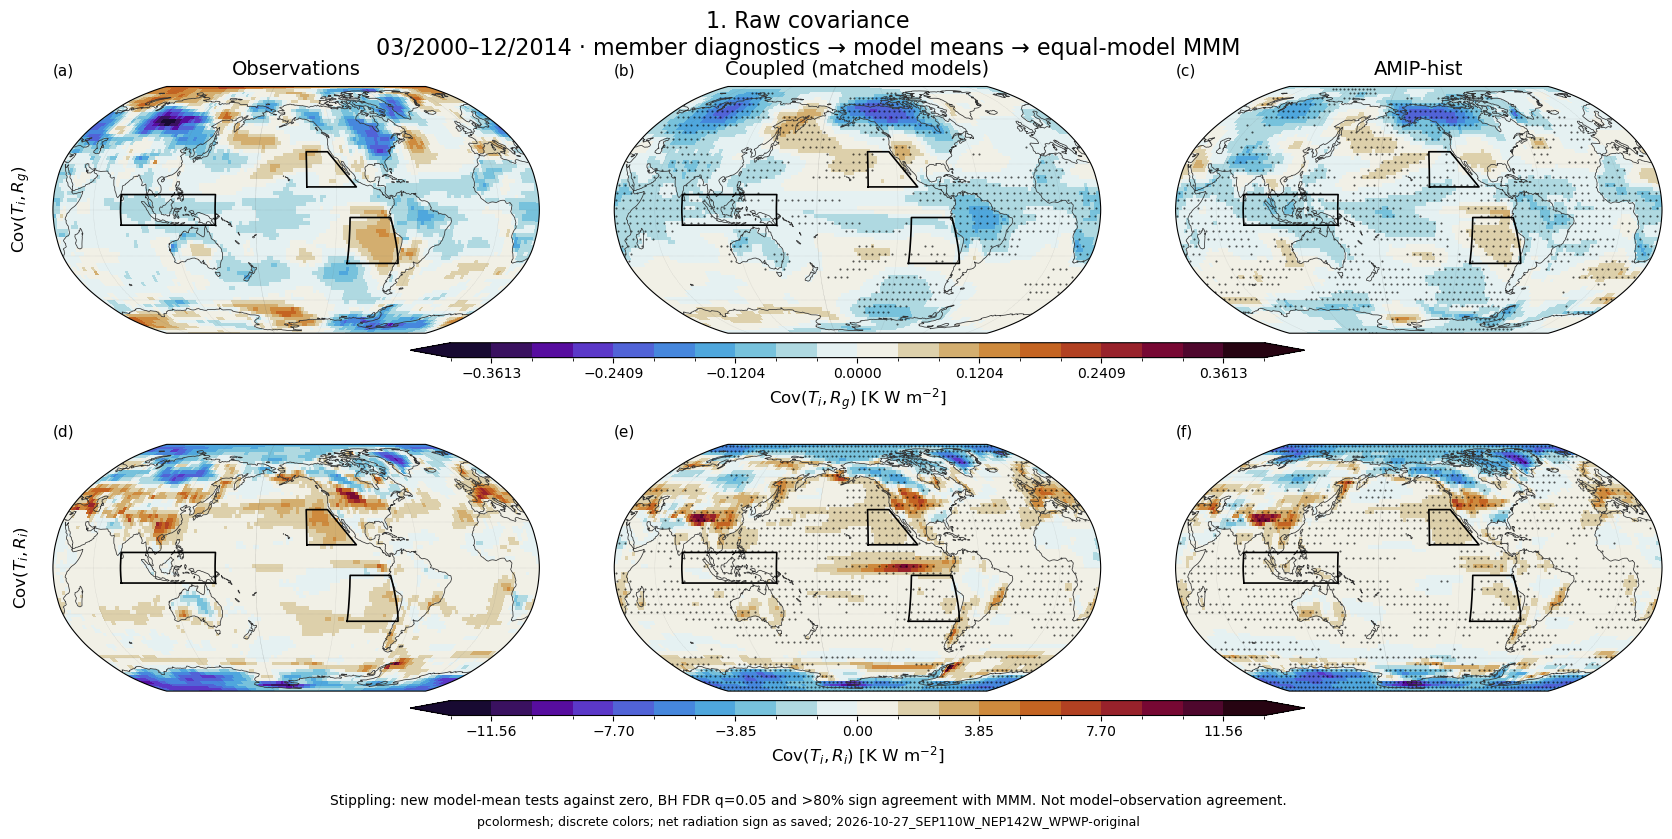

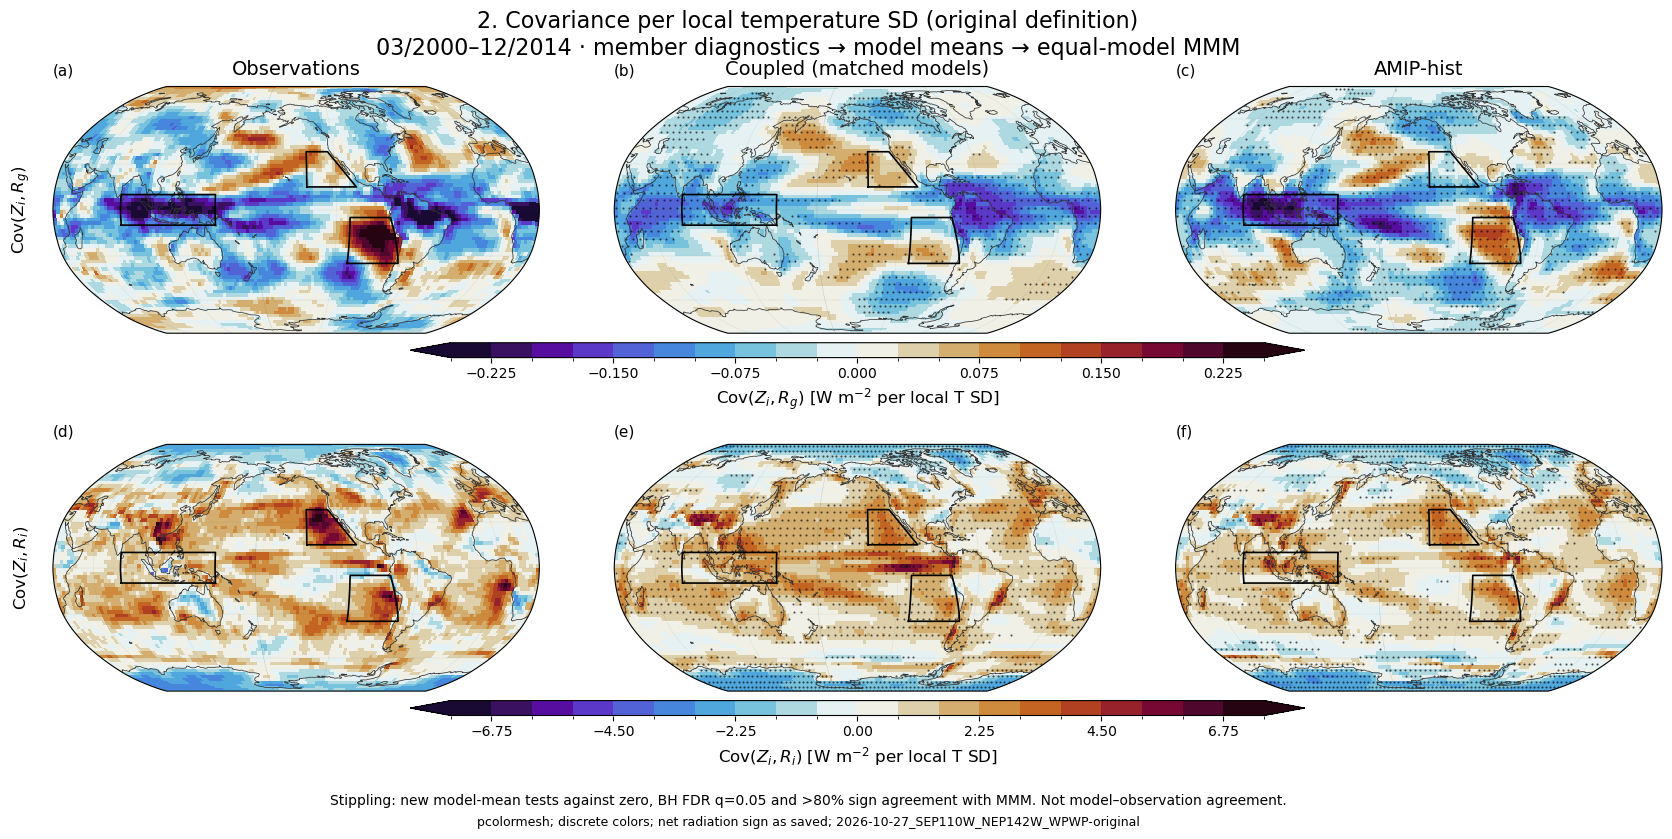

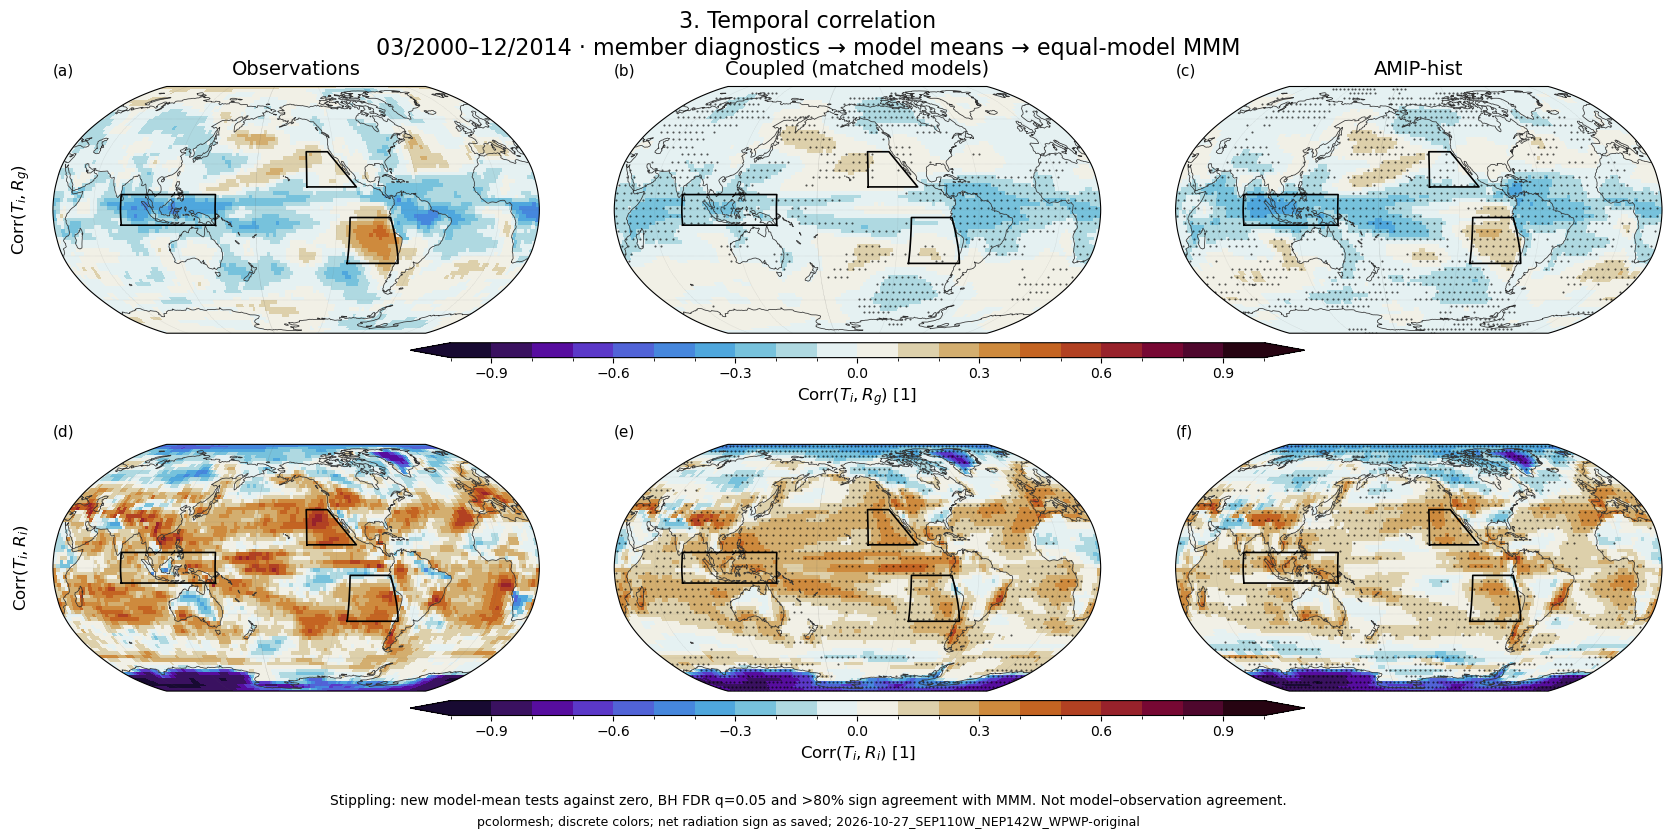

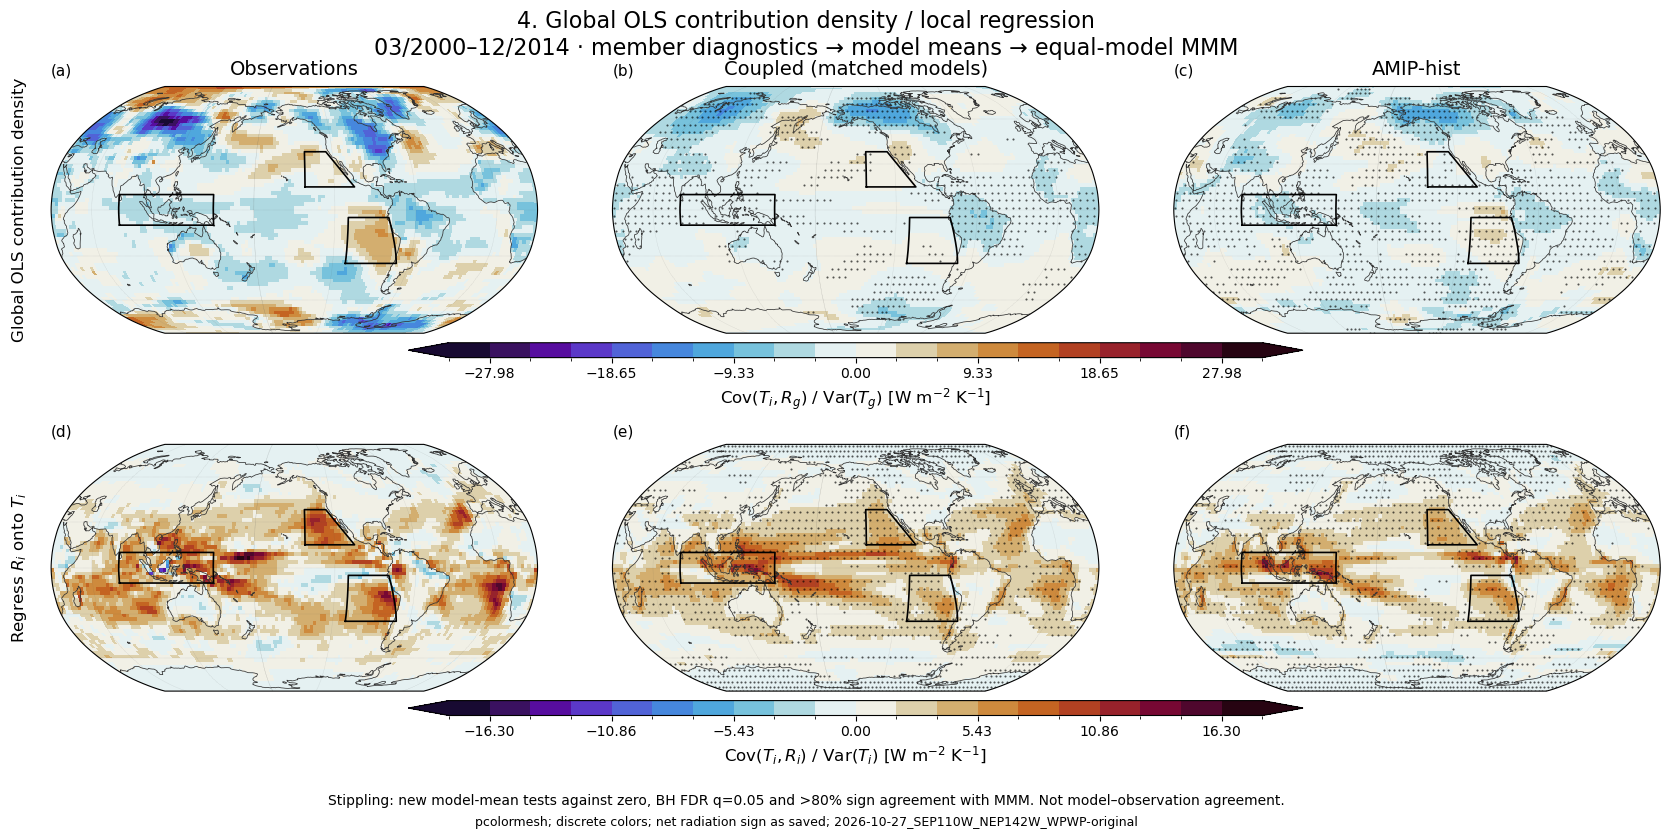

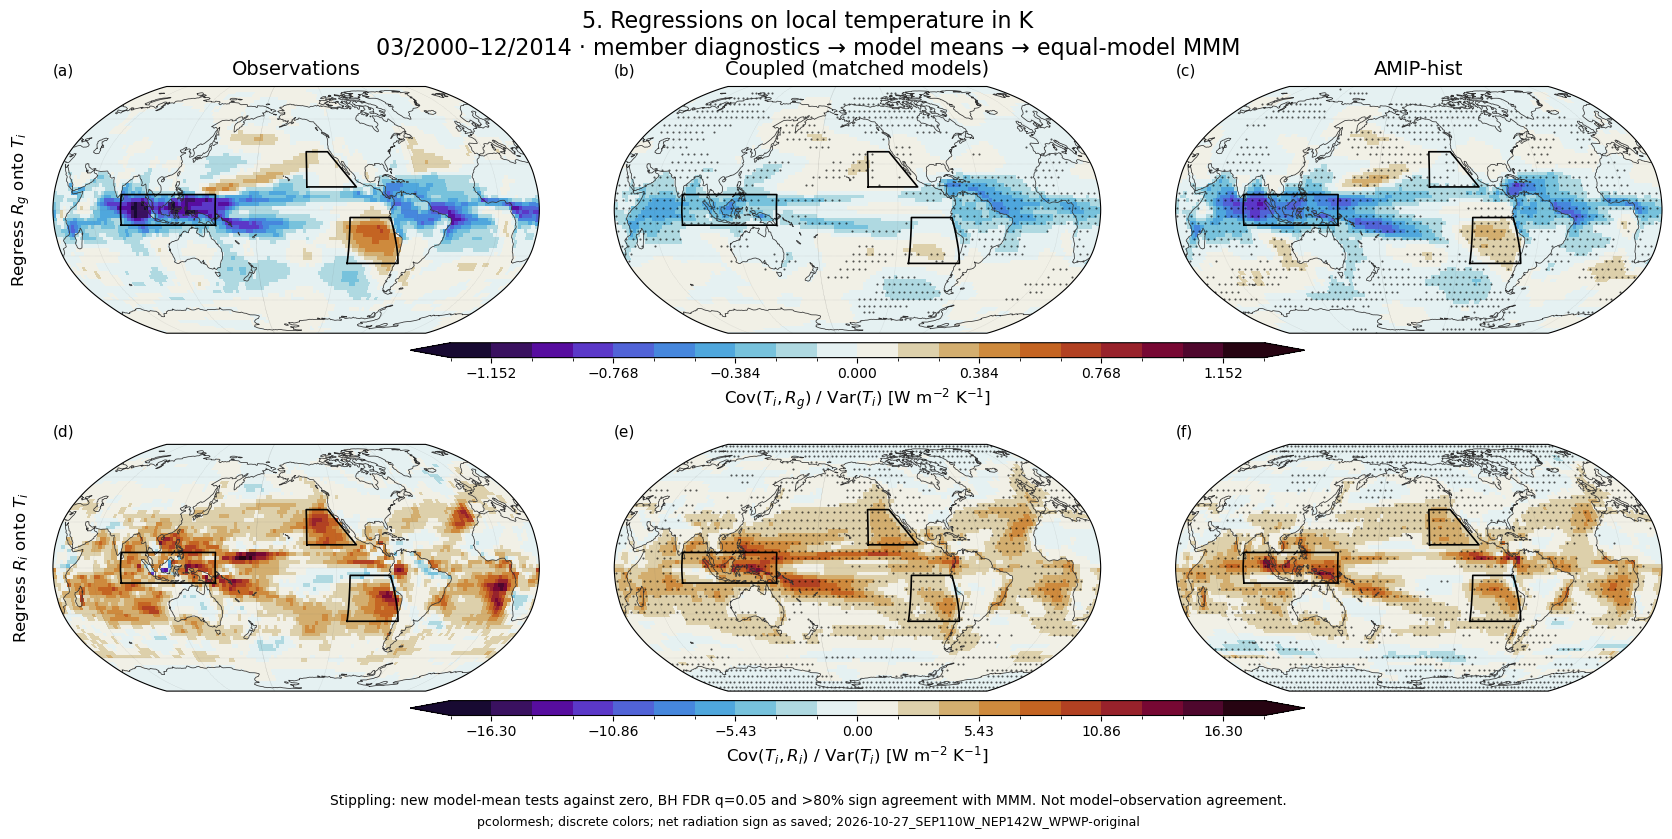

,figure,row,quantity,symmetric_limit,fraction_of_displayed_values_clipped
0,01_raw_covariance,0,cov_Ti_R,0.401447,0.000000
1,01_raw_covariance,1,cov_Ti_Ri,12.839061,0.000000
2,02_standardized_temperature,0,cov_Zi_R,0.250000,0.002218
3,02_standardized_temperature,1,cov_Zi_Ri,7.500000,0.000064
4,03_correlation,0,corr_Ti_R,1.000000,0.000000
5,03_correlation,1,corr_Ti_Ri,1.000000,0.000000
6,04_global_budget_and_local_regression,0,thompson_global,31.084210,0.000000
7,04_global_budget_and_local_regression,1,reg_Ri_on_Ti,18.106274,0.000000
8,05_local_predictor_regressions,0,reg_R_on_Ti,1.279869,0.000000
9,05_local_predictor_regressions,1,reg_Ri_on_Ti,18.106274,0.000000


In [10]:
# 8. Draw all five Figure 1 variants
# Shared quantity keys ensure that the bottom regression row in figures 4 and 5
# is identical, including its colors, support, and newly calculated stippling.
variant_labels = {
    'cov_Ti_R': (r'Cov($T_i,R_g$)', r'Cov($T_i,R_g$) [K W m$^{-2}$]'),
    'cov_Ti_Ri': (r'Cov($T_i,R_i$)', r'Cov($T_i,R_i$) [K W m$^{-2}$]'),
    'cov_Zi_R': (r'Cov($Z_i,R_g$)', r'Cov($Z_i,R_g$) [W m$^{-2}$ per local T SD]'),
    'cov_Zi_Ri': (r'Cov($Z_i,R_i$)', r'Cov($Z_i,R_i$) [W m$^{-2}$ per local T SD]'),
    'corr_Ti_R': (r'Corr($T_i,R_g$)', r'Corr($T_i,R_g$) [1]'),
    'corr_Ti_Ri': (r'Corr($T_i,R_i$)', r'Corr($T_i,R_i$) [1]'),
    'thompson_global': ('Global OLS contribution density', r'Cov($T_i,R_g$) / Var($T_g$) [W m$^{-2}$ K$^{-1}$]'),
    'reg_R_on_Ti': (r'Regress $R_g$ onto $T_i$', r'Cov($T_i,R_g$) / Var($T_i$) [W m$^{-2}$ K$^{-1}$]'),
    'reg_Ri_on_Ti': (r'Regress $R_i$ onto $T_i$', r'Cov($T_i,R_i$) / Var($T_i$) [W m$^{-2}$ K$^{-1}$]'),
}
variant_titles = {'01_raw_covariance': '1. Raw covariance',
                  '02_standardized_temperature': '2. Covariance per local temperature SD (original definition)',
                  '03_correlation': '3. Temporal correlation',
                  '04_global_budget_and_local_regression': '4. Global OLS contribution density / local regression',
                  '05_local_predictor_regressions': '5. Regressions on local temperature in K'}
variant_stats = {exp: {key: model_robustness(np.where(variant_display_mask[None], variant_model_means[exp][key], np.nan), q=fdr_q,
                      agreement_threshold=sign_threshold) for key in variant_keys} for exp in diagnostic_model_names}
variant_figures, variant_axes, color_limit_rows = {}, {}, []
for name, pair in variant_pairs.items():
    maps = np.stack([np.stack([diagnostic_observations[key], variant_MMM['historical_matched'][key],
                               variant_MMM['amip_hist'][key]]) for key in pair])
    masks = [[None] + [variant_stats[exp][key]['robust'] for exp in ['historical_matched', 'amip_hist']] for key in pair]
    output_path = results_dir / 'figures' / (name + '.png') if save_figures else None
    fig, axes, limits = plot_figure1(maps, [variant_labels[key][0] for key in pair],
                                    [variant_labels[key][1] for key in pair], variant_titles[name],
                                    diagnostic_coordinates, diagnostic_regions, plot_method=plot_method,
                                    color_binning=color_binning, vlims=[variant_vlims[key] for key in pair],
                                    cmap=cmap_name, central_longitude=central_longitude,
                                    robust_masks=masks if show_stippling else None, show_regions=show_regions,
                                    display_mask=variant_display_mask, savepath=output_path,
                                    overwrite=overwrite, dpi=figure_dpi)
    variant_figures[name], variant_axes[name] = fig, axes
    for row, key in enumerate(pair):
        displayed = maps[row][:, variant_display_mask]
        color_limit_rows.append({'figure': name, 'row': row, 'quantity': key, 'symmetric_limit': limits[row],
                                  'fraction_of_displayed_values_clipped': float(np.mean(np.abs(displayed) > limits[row]))})
    plt.show()
color_limit_table = pd.DataFrame(color_limit_rows)
display(color_limit_table)